In [1]:
import pandas as pd
from pathlib import Path
from climate_health_map.shared import read_any_pd
from sklearn.metrics import classification_report
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go

## Load data

In [ ]:
legacy = pd.read_csv('data/enhanced/20260929/legacy.csv').set_index('item_id')
legacy['rel_major'] = legacy[['rel_major|0', 'rel_major|1']].idxmax(axis=1)
legacy['cat'] = legacy[['cat|0', 'cat|1',  'cat|2']].idxmax(axis=1)
legacy.sample(5)

,rel_major|0,rel_major|1,cat|2,cat|1,cat|0,rel_major,cat
item_id,,,,,,,
b36c2379-5fef-4e49-947e-c992168530db,0.963578,0.036422,0.035061,0.023253,0.020014,rel_major|0,cat|2
8689423a-418e-402d-96ab-1b8a13396d02,0.911114,0.088886,0.056059,0.159993,0.028425,rel_major|0,cat|1
9461c465-05bf-486d-be58-65eb086b7e7f,0.946557,0.053443,0.070554,0.020704,0.013926,rel_major|0,cat|2
fae55caa-a74a-4790-8dc7-e985e8d1444d,0.957238,0.042762,0.088535,0.040476,0.005532,rel_major|0,cat|2
a5d9786b-9134-422f-9e0c-02f143f670d2,0.958497,0.041503,0.076049,0.083613,0.014809,rel_major|0,cat|1


In [ ]:
rel_major = read_any_pd(Path('data/enhanced/20260929/labels_rel_major.arrow'))
rel_cat = read_any_pd(Path('data/enhanced/20260929/labels_cat.arrow'))
new = rel_major.merge(rel_cat, on='item_id', how='inner').set_index('item_id')
new['rel_major'] = new[['rel_major|0', 'rel_major|1']].idxmax(axis=1)
new['cat'] = new[['cat|0', 'cat|1',  'cat|2']].idxmax(axis=1)
new.sample(5)

,rel_major|1,rel_major|0,cat|0,cat|1,cat|2,rel_major,cat
item_id,,,,,,,
b43711ce-a2e0-478f-b14d-f22e8d71653f,0.000071,0.999566,0.999910,0.040082,0.003547,rel_major|0,cat|0
8775c9b2-2280-4c6c-af3b-db111cdcfa26,0.999960,0.000168,0.000027,0.999956,0.996705,rel_major|1,cat|1
597fae12-b3a3-460f-8a65-197bbcc7fad8,0.000050,0.999667,0.000039,0.001243,0.968633,rel_major|0,cat|2
2be5005c-2cdb-49d5-a549-219a49d1f788,0.000052,0.999673,0.000095,0.131906,0.006520,rel_major|0,cat|1
d5e6365c-2281-437a-9bd2-aec25c9ac78e,0.000058,0.999713,0.999916,0.000128,0.047115,rel_major|0,cat|0


In [4]:
# Build side-by-side comparison frames (inner join on item_id) for each task.
# `*_legacy` / `*_new` columns hold the predicted class from each model.
rels = (
    legacy[["rel_major"]]
    .merge(new[["rel_major"]], how="inner", on="item_id", suffixes=["_legacy", "_new"])
)
cats = (
    legacy[["cat"]]
    .merge(new[["cat"]], how="inner", on="item_id", suffixes=["_legacy", "_new"])
)

print("rel_major comparison:", rels.shape)
print("cat comparison:      ", cats.shape)
rels.sample(5)

rel_major comparison: (133214, 2)
cat comparison:       (133214, 2)


,rel_major_legacy,rel_major_new
item_id,,
ed73b178-8096-40a1-9903-a15848f4b59d,rel_major|0,rel_major|1
0f4e82a7-8f32-4bcc-859c-d1361ced8df2,rel_major|1,rel_major|1
cbc6feb0-5cfc-45c5-a4e9-cb8871220886,rel_major|1,rel_major|0
6303fed0-ee73-4ccb-86e0-f26d182f44c0,rel_major|0,rel_major|0
7a2a95f9-4df4-48ac-af6d-792f41aed504,rel_major|1,rel_major|0


## Overall agreement

A quick `classification_report` for each task, treating the legacy model as the
reference. This gives per-class precision / recall / F1 for how well the new model
matches the legacy one.

In [5]:
# Binary task: legacy as reference vs new, and the reverse.
print("rel_major — legacy as reference:")
print(classification_report(legacy.rel_major, new.rel_major))
print("rel_major — new as reference:")
print(classification_report(new.rel_major, legacy.rel_major))

rel_major — legacy as reference:
              precision    recall  f1-score   support

 rel_major|0       0.99      0.90      0.94    124999
 rel_major|1       0.36      0.86      0.50      8215

    accuracy                           0.90    133214
   macro avg       0.67      0.88      0.72    133214
weighted avg       0.95      0.90      0.91    133214

rel_major — new as reference:
              precision    recall  f1-score   support

 rel_major|0       0.90      0.99      0.94    113341
 rel_major|1       0.86      0.36      0.50     19873

    accuracy                           0.90    133214
   macro avg       0.88      0.67      0.72    133214
weighted avg       0.89      0.90      0.88    133214



In [6]:
# 3-class task: legacy as reference vs new, and the reverse.
print("cat — legacy as reference:")
print(classification_report(legacy.cat, new.cat))
print("cat — new as reference:")
print(classification_report(new.cat, legacy.cat))

cat — legacy as reference:
              precision    recall  f1-score   support

       cat|0       0.50      0.53      0.51     13171
       cat|1       0.60      0.44      0.51     53933
       cat|2       0.63      0.76      0.68     66110

    accuracy                           0.61    133214
   macro avg       0.58      0.57      0.57    133214
weighted avg       0.60      0.61      0.60    133214

cat — new as reference:
              precision    recall  f1-score   support

       cat|0       0.53      0.50      0.51     13880
       cat|1       0.44      0.60      0.51     39281
       cat|2       0.76      0.63      0.68     80053

    accuracy                           0.61    133214
   macro avg       0.57      0.58      0.57    133214
weighted avg       0.64      0.61      0.61    133214



## Binary task (`rel_major`)

The `rel_major` task is binary (`rel_major|0` = not relevant, `rel_major|1` = relevant).
We visualise the legacy → new transitions three ways: **pie charts**, a **heatmap**,
and a **Sankey diagram**.

In [7]:
# Flag each item by how its binary prediction changed between the two models:
#   - old_rel_new_not : legacy said relevant, new says not relevant
#   - new_rel_old_not : legacy said not relevant, new says relevant
#   - same            : both models agree
rels["old_rel_new_not"] = 0
rels["new_rel_old_not"] = 0
rels["same"] = 0

rels.loc[(rels.rel_major_legacy == "rel_major|1") & (rels.rel_major_new == "rel_major|0"), "old_rel_new_not"] = 1
rels.loc[(rels.rel_major_legacy == "rel_major|0") & (rels.rel_major_new == "rel_major|1"), "new_rel_old_not"] = 1
rels.loc[rels.rel_major_legacy == rels.rel_major_new, "same"] = 1

# Proportion of items in each outcome category.
rel_changes = rels[["old_rel_new_not", "new_rel_old_not", "same"]].sum() / rels.shape[0]
rel_changes

old_rel_new_not    0.008618
new_rel_old_not    0.096131
same               0.895251
dtype: float64

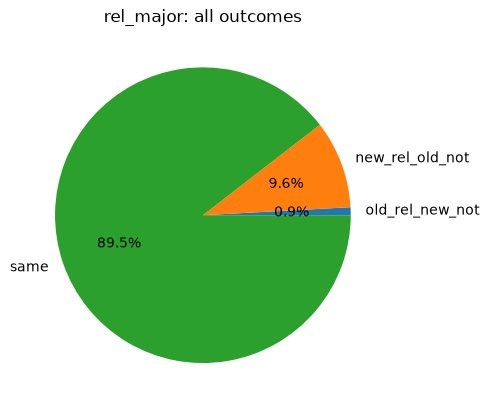

In [8]:
# Pie chart: full breakdown of the binary task (agreement + both change directions).
rel_changes.plot(kind="pie", autopct="%1.1f%%", title="rel_major: all outcomes")
plt.show()

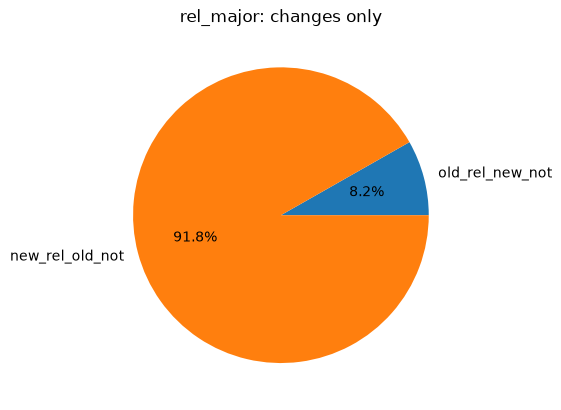

In [9]:
# Pie chart: only the two change directions, showing which way the model drifts.
rel_changes.drop("same").plot(kind="pie", autopct="%1.1f%%", title="rel_major: changes only")
plt.show()

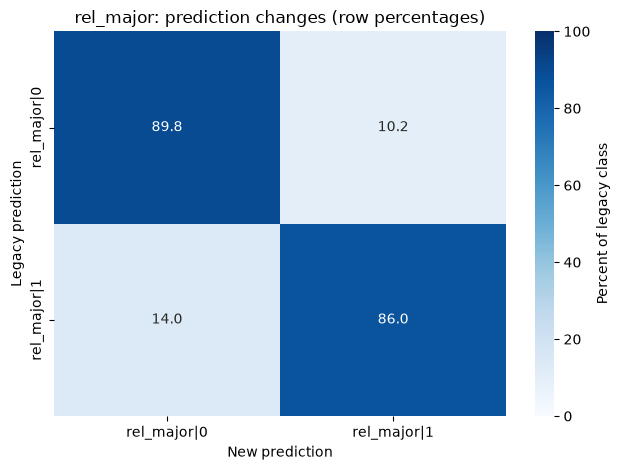

In [10]:
# Heatmap: row-normalised transition matrix for the binary `rel_major` task.
# Each row shows how a legacy class is redistributed across the new classes.
classes = ["rel_major|0", "rel_major|1"]

counts = pd.crosstab(rels["rel_major_legacy"], rels["rel_major_new"]).reindex(
    index=classes, columns=classes, fill_value=0
)
row_pct = counts.div(counts.sum(axis=1).replace(0, 1), axis=0) * 100

sns.heatmap(
    row_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percent of legacy class"},
)
plt.xlabel("New prediction")
plt.ylabel("Legacy prediction")
plt.title("rel_major: prediction changes (row percentages)")
plt.tight_layout()
plt.show()

In [11]:
# Sankey diagram: flow of items from each legacy class to each new class.
flows = (
    rels.groupby(["rel_major_legacy", "rel_major_new"])
    .size()
    .reset_index(name="count")
)

total = flows["count"].sum()
legacy_totals = flows.groupby("rel_major_legacy")["count"].sum()
flows["pct_total"] = 100 * flows["count"] / total
flows["pct_legacy"] = flows.apply(
    lambda r: 100 * r["count"] / legacy_totals[r["rel_major_legacy"]], axis=1
)

classes = sorted(set(rels["rel_major_legacy"].dropna()) | set(rels["rel_major_new"].dropna()))

# Separate node sets for the two sides so matching labels appear on both.
labels = [f"Legacy: {c}" for c in classes] + [f"New: {c}" for c in classes]
legacy_nodes = {c: i for i, c in enumerate(classes)}
new_nodes = {c: i + len(classes) for i, c in enumerate(classes)}

fig = go.Figure(go.Sankey(
    node=dict(label=labels, pad=20, thickness=20),
    link=dict(
        source=[legacy_nodes[c] for c in flows["rel_major_legacy"]],
        target=[new_nodes[c] for c in flows["rel_major_new"]],
        value=flows["count"],
        customdata=flows[["pct_total", "pct_legacy"]].to_numpy(),
        hovertemplate=(
            "%{source.label} → %{target.label}<br>"
            "Count: %{value}<br>"
            "Of all records: %{customdata[0]:.1f}%<br>"
            "Of legacy class: %{customdata[1]:.1f}%"
            "<extra></extra>"
        ),
    ),
))
fig.update_layout(title_text="rel_major: prediction changes (legacy → new)", font_size=12)
fig.show()

### Conclusion

New classifier and old classifier agree 90% of the time. And when they disagree, the new classifier does mostly switch not relevant items to relevant items. This is in line with the hypothesis that new model was trained to inlcude more items as relevant. Only a small percentage. 
- **0.9%** of overall records where labelled as non-relevant when the legacy classifier had labelled them as relevant. 
- Of all the changes, this relates to **8.4%** 
- If we are interested in the new classifier's classification in the legacy classifier's relevant class only, 14% were reversed, and classified as non-relevant by the new classifier.

## 3-class task (`cat`)

The `cat` task has three classes (`cat|0`, `cat|1`, `cat|2`). We visualise the
legacy → new transitions with a **heatmap** and a **Sankey diagram**.

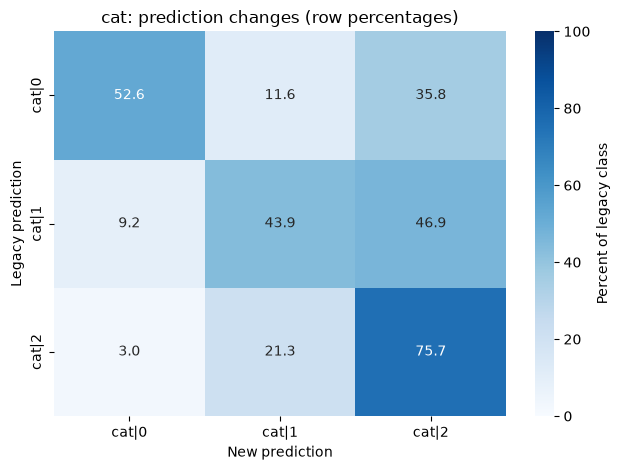

In [12]:
# Heatmap: row-normalised transition matrix for the 3-class `cat` task.
# Each row shows how a legacy class is redistributed across the new classes.
classes = ["cat|0", "cat|1", "cat|2"]

counts = pd.crosstab(cats["cat_legacy"], cats["cat_new"]).reindex(
    index=classes, columns=classes, fill_value=0
)
row_pct = counts.div(counts.sum(axis=1).replace(0, 1), axis=0) * 100

sns.heatmap(
    row_pct,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    cbar_kws={"label": "Percent of legacy class"},
)
plt.xlabel("New prediction")
plt.ylabel("Legacy prediction")
plt.title("cat: prediction changes (row percentages)")
plt.tight_layout()
plt.show()

In [13]:
# Sankey diagram: flow of items from each legacy class to each new class.
flows = (
    cats.groupby(["cat_legacy", "cat_new"])
    .size()
    .reset_index(name="count")
)

total = flows["count"].sum()
legacy_totals = flows.groupby("cat_legacy")["count"].sum()
flows["pct_total"] = 100 * flows["count"] / total
flows["pct_legacy"] = flows.apply(
    lambda r: 100 * r["count"] / legacy_totals[r["cat_legacy"]], axis=1
)

classes = sorted(set(cats["cat_legacy"].dropna()) | set(cats["cat_new"].dropna()))

# Separate node sets for the two sides so matching labels appear on both.
labels = [f"Legacy: {c}" for c in classes] + [f"New: {c}" for c in classes]
legacy_nodes = {c: i for i, c in enumerate(classes)}
new_nodes = {c: i + len(classes) for i, c in enumerate(classes)}

fig = go.Figure(go.Sankey(
    node=dict(label=labels, pad=20, thickness=20),
    link=dict(
        source=[legacy_nodes[c] for c in flows["cat_legacy"]],
        target=[new_nodes[c] for c in flows["cat_new"]],
        value=flows["count"],
        customdata=flows[["pct_total", "pct_legacy"]].to_numpy(),
        hovertemplate=(
            "%{source.label} → %{target.label}<br>"
            "Count: %{value}<br>"
            "Of all records: %{customdata[0]:.1f}%<br>"
            "Of legacy class: %{customdata[1]:.1f}%"
            "<extra></extra>"
        ),
    ),
))
fig.update_layout(title_text="cat: prediction changes (legacy → new)", font_size=12)
fig.show()

### Plotting only the changes

Plot the cases where the new and legacy classifier disagreed, ignoring their agreements

In [14]:
cats_changes = cats[(cats.cat_legacy != cats.cat_new)]
print('Percentage of classes changed:', cats_changes.shape[0]/cats.shape[0])

# Sankey diagram: flow of items from each legacy class to each new class.
flows = (
    cats_changes.groupby(["cat_legacy", "cat_new"])
    .size()
    .reset_index(name="count")
)

total = flows["count"].sum()
legacy_totals = flows.groupby("cat_legacy")["count"].sum()
flows["pct_total"] = 100 * flows["count"] / total
flows["pct_legacy"] = flows.apply(
    lambda r: 100 * r["count"] / legacy_totals[r["cat_legacy"]], axis=1
)

classes = sorted(set(cats_changes["cat_legacy"].dropna()) | set(cats_changes["cat_new"].dropna()))

# Separate node sets for the two sides so matching labels appear on both.
labels = [f"Legacy: {c}" for c in classes] + [f"New: {c}" for c in classes]
legacy_nodes = {c: i for i, c in enumerate(classes)}
new_nodes = {c: i + len(classes) for i, c in enumerate(classes)}

fig = go.Figure(go.Sankey(
    node=dict(label=labels, pad=20, thickness=20),
    link=dict(
        source=[legacy_nodes[c] for c in flows["cat_legacy"]],
        target=[new_nodes[c] for c in flows["cat_new"]],
        value=flows["count"],
        customdata=flows[["pct_total", "pct_legacy"]].to_numpy(),
        hovertemplate=(
            "%{source.label} → %{target.label}<br>"
            "Count: %{value}<br>"
            "Of all records: %{customdata[0]:.1f}%<br>"
            "Of legacy class: %{customdata[1]:.1f}%"
            "<extra></extra>"
        ),
    ),
))
fig.update_layout(title_text="cat: prediction changes (legacy → new)", font_size=12)
fig.show()

Percentage of classes changed: 0.3943054033359857


In [15]:
flows

,cat_legacy,cat_new,count,pct_total,pct_legacy
0,cat|0,cat|1,1523,2.899461,24.403141
1,cat|0,cat|2,4718,8.982047,75.596859
2,cat|1,cat|0,4951,9.425629,16.377229
3,cat|1,cat|2,25280,48.127630,83.622771
4,cat|2,cat|0,1999,3.805662,12.450950
5,cat|2,cat|1,14056,26.759571,87.549050


### Conclusion

With the 3-class case, degree of agreement dropped to **60%**. Particularly for `cat|1`, only 44% of classifications remained the same and majority of new classifications changed.  **84.6%** of these changes were to `cat|2` while the rest was to `cat|0`

Reverting this change in overall visibility, **88%** of `cat|2` changes were changed to `cat|1`.

However, the magnitude of the change in `cat|1` -> `cat|2` direction was much bigger. As a result of this, class distributions between the two classifiers have changed, even though their frequency rankings did not change (that is count(`cat|2`) > count(`cat|1`) > count(`cat|0`) for both classifiers). 

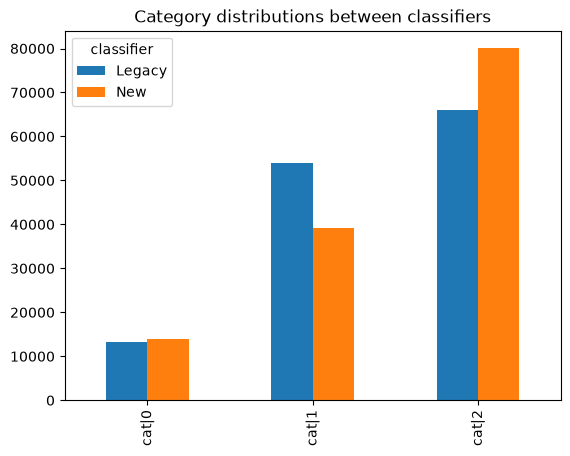

In [16]:
cats[["cat_legacy", "cat_new"]].rename(columns={'cat_legacy': 'Legacy', 'cat_new': 'New'}).apply(
    lambda col: col.value_counts()
).sort_index().plot(kind="bar")

plt.title('Category distributions between classifiers')
plt.legend(title='classifier')
plt.show()